# LOAD DATA

In [1]:
# Load all image file paths from the dataset directory and create a DataFrame
# with image paths, class IDs (0 or 1), and class names (With/Without Covid).
# This creates our master dataset that we'll use for training, validation, and testing.

import os
import glob
import pandas as pd

BASE_DIR = "../data/DATA/DATA"

label_map = {
    0: "Without Covid",
    1: "With Covid"
}

rows = []

for class_id in [0, 1]:
    class_dir = os.path.join(BASE_DIR, str(class_id))
    
    # get all image files
    img_paths = glob.glob(os.path.join(class_dir, "*.*"))
    
    for img_path in img_paths:
        if img_path.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append({
                "image_path": img_path,
                "class_id": class_id,
                "class_name": label_map[class_id]
            })

df = pd.DataFrame(rows)

df.head()


,image_path,class_id,class_name
0,../data/DATA/DATA\0\IM-0115-0001.jpeg,0,Without Covid
1,../data/DATA/DATA\0\IM-0119-0001.jpeg,0,Without Covid
2,../data/DATA/DATA\0\IM-0122-0001.jpeg,0,Without Covid
3,../data/DATA/DATA\0\IM-0125-0001.jpeg,0,Without Covid
4,../data/DATA/DATA\0\IM-0127-0001.jpeg,0,Without Covid


In [2]:
# Check the class distribution in our dataset
# This helps us understand if we have class imbalance issues

df['class_name'].value_counts()

class_name
With Covid       1790
Without Covid    1301
Name: count, dtype: int64

In [3]:
# Verify image dimensions across the dataset
# X-ray images often come in different sizes, so we need to check
# how many unique dimensions exist before standardizing them

from tensorflow.keras.utils import load_img
import numpy as np

all_sizes = set()

for p in df["image_path"]:
    img = load_img(p)
    all_sizes.add(img.size)

print("All unique image sizes:", len(all_sizes))

# 2871 out of 3071 images are unique which is kinda bad

All unique image sizes: 2871


# PLOTS

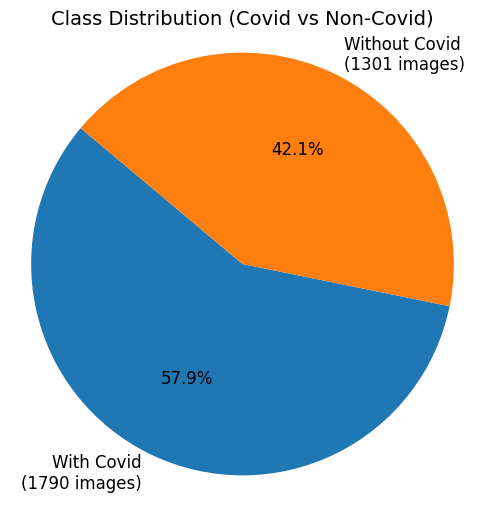

In [4]:
# Create a pie chart to visualize the class distribution
# This shows the proportion of COVID vs non-COVID X-ray images

import matplotlib.pyplot as plt

class_counts = df["class_name"].value_counts()
labels = class_counts.index
sizes = class_counts.values

plt.figure(figsize=(6,6))
plt.pie(
    sizes,
    labels=[f"{label}\n({count} images)" for label, count in zip(labels, sizes)],
    autopct="%1.1f%%",
    startangle=140,
    textprops={'fontsize': 12}
)
plt.title("Class Distribution (Covid vs Non-Covid)", fontsize=14)
plt.axis("equal")
plt.show()


In [5]:
# Extract width, height, and class information for every image in the dataset
# This creates a separate DataFrame to analyze image dimension patterns
# and their relationship with class labels

from tensorflow.keras.utils import load_img
import tqdm
import pandas as pd

widths = []
heights = []
class_ids = []
class_names = []

for idx, row in tqdm.tqdm(df.iterrows(), total=len(df)):
    img = load_img(row["image_path"])
    w, h = img.size  
    widths.append(w)
    heights.append(h)
    class_ids.append(row["class_id"])
    class_names.append(row["class_name"])

df_sizes = pd.DataFrame({
    "width": widths,
    "height": heights,
    "class_id": class_ids,
    "class_name": class_names
})

df_sizes.head()

100%|████████████████████████████████████████████████████████████████████████████| 3091/3091 [00:02<00:00, 1240.42it/s]


,width,height,class_id,class_name
0,2090,1858,0,Without Covid
1,1810,1434,0,Without Covid
2,1618,1279,0,Without Covid
3,1600,1125,0,Without Covid
4,1974,1306,0,Without Covid


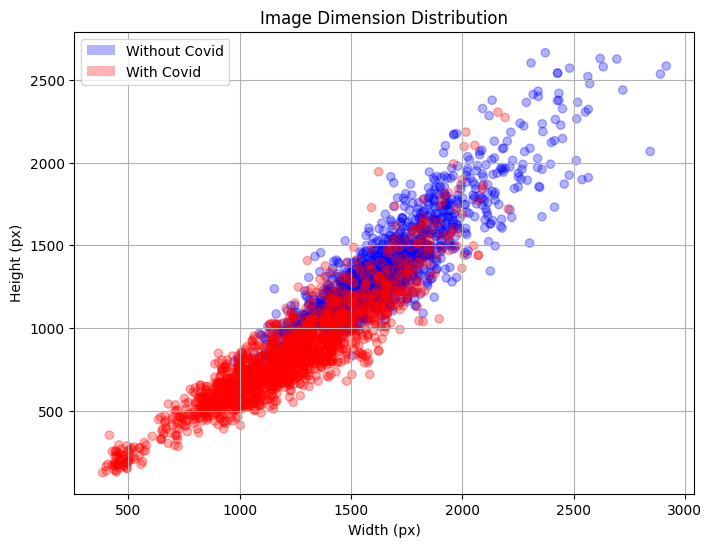

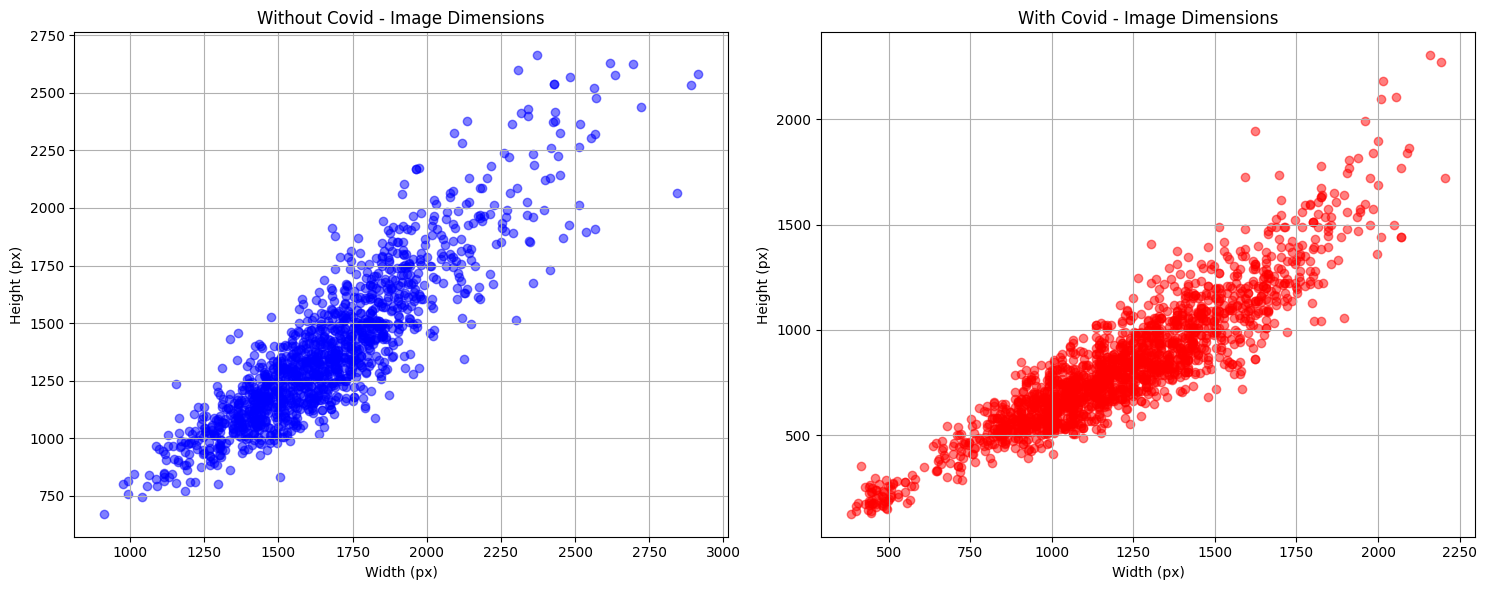

In [6]:
# Create scatter plots to visualize image dimensions by class
# Top plot: Combined view with color-coded classes (blue=without, red=with COVID)
# Bottom plots: Separate views for each class to identify dimension patterns

plt.figure(figsize=(8,6))

colors = df_sizes["class_id"].map({0: "blue", 1: "red"})

plt.scatter(df_sizes["width"], df_sizes["height"], alpha=0.3, c=colors)
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.title("Image Dimension Distribution")
plt.grid(True)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='blue', alpha=0.3, label='Without Covid'),
    Patch(facecolor='red', alpha=0.3, label='With Covid')
]
plt.legend(handles=legend_elements)

# Create subplots for individual classes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot for Without Covid (class 0)
without_covid = df_sizes[df_sizes["class_id"] == 0]
ax1.scatter(without_covid["width"], without_covid["height"], alpha=0.5, c="blue")
ax1.set_xlabel("Width (px)")
ax1.set_ylabel("Height (px)")
ax1.set_title("Without Covid - Image Dimensions")
ax1.grid(True)

# Plot for With Covid (class 1)
with_covid = df_sizes[df_sizes["class_id"] == 1]
ax2.scatter(with_covid["width"], with_covid["height"], alpha=0.5, c="red")
ax2.set_xlabel("Width (px)")
ax2.set_ylabel("Height (px)")
ax2.set_title("With Covid - Image Dimensions")
ax2.grid(True)

plt.tight_layout()
plt.show()

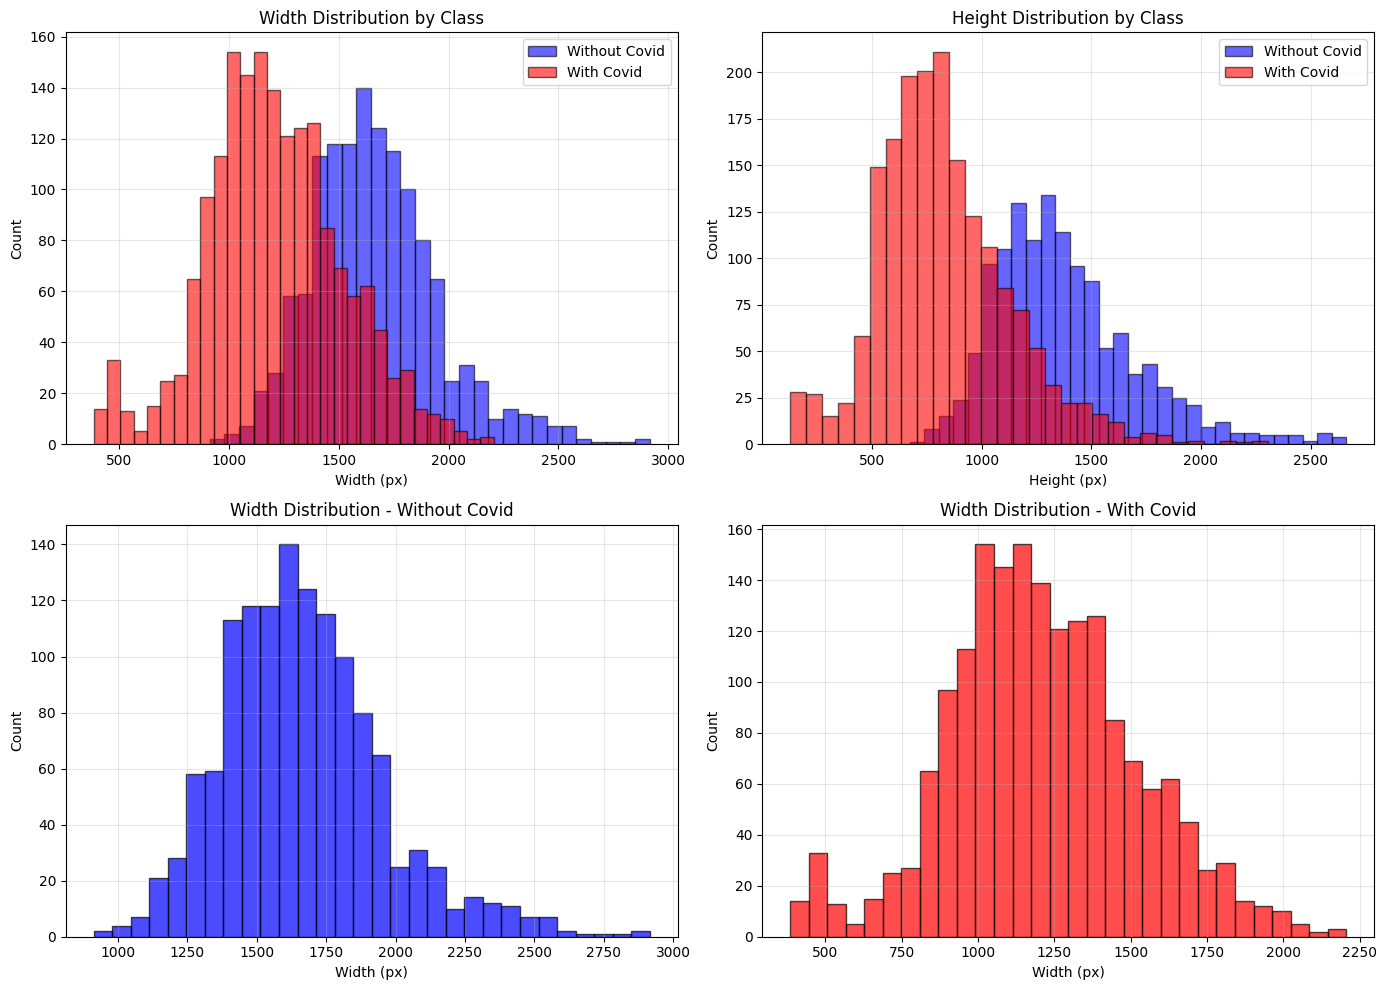

In [7]:
# Create histograms showing the distribution of image widths and heights
# Top row: Overlapping histograms comparing COVID vs non-COVID dimensions
# Bottom row: Individual histograms for each class to see detailed distributions

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

without_covid = df_sizes[df_sizes["class_id"] == 0]
with_covid = df_sizes[df_sizes["class_id"] == 1]

# Width distribution by class
axes[0, 0].hist(without_covid["width"], bins=30, color="blue", alpha=0.6, edgecolor="black", label="Without Covid")
axes[0, 0].hist(with_covid["width"], bins=30, color="red", alpha=0.6, edgecolor="black", label="With Covid")
axes[0, 0].set_title("Width Distribution by Class")
axes[0, 0].set_xlabel("Width (px)")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Height distribution by class
axes[0, 1].hist(without_covid["height"], bins=30, color="blue", alpha=0.6, edgecolor="black", label="Without Covid")
axes[0, 1].hist(with_covid["height"], bins=30, color="red", alpha=0.6, edgecolor="black", label="With Covid")
axes[0, 1].set_title("Height Distribution by Class")
axes[0, 1].set_xlabel("Height (px)")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Width - Without Covid only
axes[1, 0].hist(without_covid["width"], bins=30, color="blue", alpha=0.7, edgecolor="black")
axes[1, 0].set_title("Width Distribution - Without Covid")
axes[1, 0].set_xlabel("Width (px)")
axes[1, 0].set_ylabel("Count")
axes[1, 0].grid(True, alpha=0.3)

# Width - With Covid only
axes[1, 1].hist(with_covid["width"], bins=30, color="red", alpha=0.7, edgecolor="black")
axes[1, 1].set_title("Width Distribution - With Covid")
axes[1, 1].set_xlabel("Width (px)")
axes[1, 1].set_ylabel("Count")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

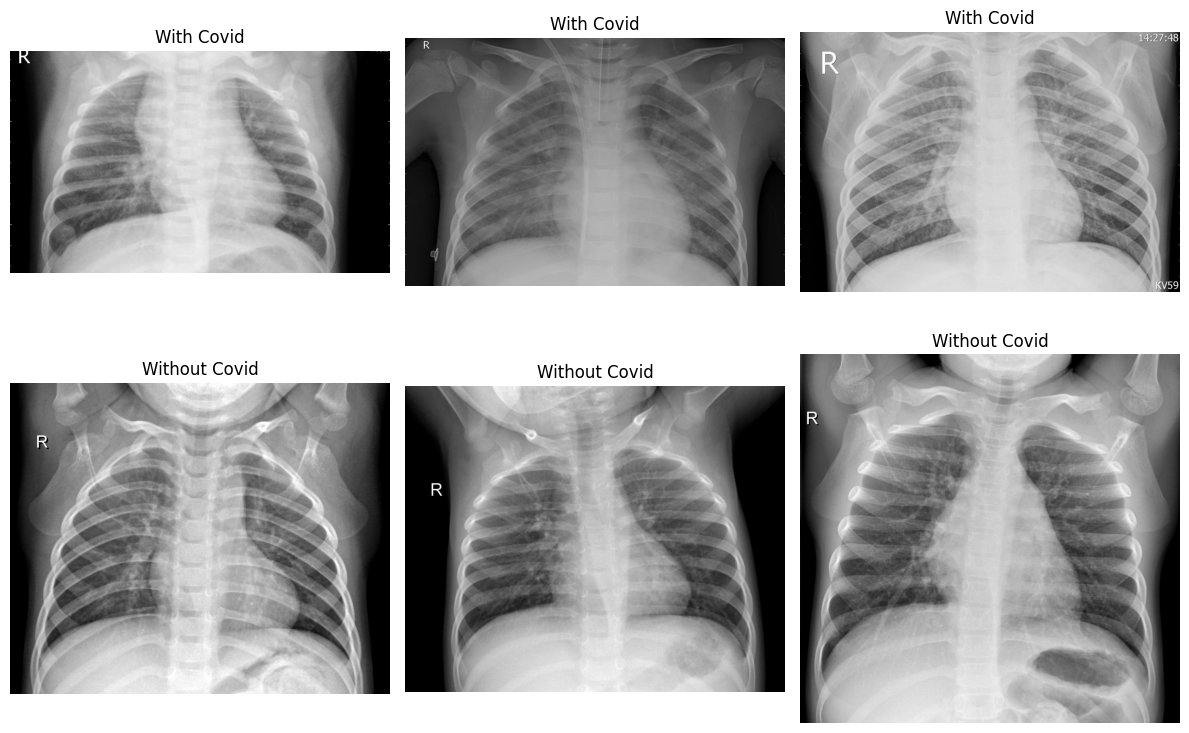

In [8]:
# Display a random sample of images from the dataset
# Shows 3 COVID and 3 non-COVID X-rays to visually inspect data quality
# and understand what the images look like before preprocessing

import matplotlib.pyplot as plt

def show_random_grid(df, n_per_class=3):
    covid_sample = df[df["class_id"] == 1].sample(n_per_class)
    non_covid_sample = df[df["class_id"] == 0].sample(n_per_class)
    
    samples = pd.concat([covid_sample, non_covid_sample])
    
    plt.figure(figsize=(12, 8))

    for i, (_, row) in enumerate(samples.iterrows()):
        img = load_img(row["image_path"])
        plt.subplot(2, 3, i+1)
        plt.imshow(img, cmap="gray")
        plt.title(row["class_name"])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    return samples

samples = show_random_grid(df, n_per_class=3)

# DATA PREPROCESSING

In [9]:
# Split the dataset into training (70%), validation (15%), and test (15%) sets
# Uses stratified splitting to maintain the same class distribution in each split
# Random state is set for reproducibility

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df["class_id"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["class_id"],
    random_state=42
)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 2163
Val: 464
Test: 464


In [10]:
# Verify that stratified splitting worked correctly
# Each split should have approximately the same proportion of COVID vs non-COVID cases
# This prevents biased model training or evaluation

print("Train Set:")
print(train_df["class_name"].value_counts(normalize=True))
print("\nValidation Set:")
print(val_df["class_name"].value_counts(normalize=True))
print("\nTest Set:")
print(test_df["class_name"].value_counts(normalize=True))

# all classes equal now

Train Set:
class_name
With Covid       0.579288
Without Covid    0.420712
Name: proportion, dtype: float64

Validation Set:
class_name
With Covid       0.579741
Without Covid    0.420259
Name: proportion, dtype: float64

Test Set:
class_name
With Covid       0.577586
Without Covid    0.422414
Name: proportion, dtype: float64


In [11]:
# Define preprocessing and augmentation functions for the image pipeline
# preprocess(): Loads, decodes, converts to grayscale, resizes to 224x224, and normalizes images
# augment(): Applies random transformations (flips, brightness, contrast, rotation) to training data
# These help the model generalize better and prevent overfitting on limited data

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    # Convert to grayscale if needed (---------------------------------------------NOT NEEDED---------------------------------------------------------)
    # img = tf.image.rgb_to_grayscale(img)
    img = tf.image.resize(img, IMG_SIZE)
    img = img / 255.0  # Normalize to [0, 1]
    return img, label

def augment(img, label):
    """Apply data augmentation for training"""
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.1)
    img = tf.image.random_contrast(img, lower=0.9, upper=1.1)
    # Add slight rotation
    img = tf.image.rot90(img, k=tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32))
    img = tf.clip_by_value(img, 0.0, 1.0)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

In [12]:
# Create TensorFlow datasets from the pandas DataFrames
# Training set: shuffled with data augmentation to increase variety
# Validation/Test sets: no shuffling or augmentation for consistent evaluation
# All datasets are batched and prefetched for efficient training

def make_dataset(df, shuffle=False, augment_data=False):
    paths = df["image_path"].values
    labels = df["class_id"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(len(df), reshuffle_each_iteration=True)

    ds = ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    
    if augment_data:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, shuffle=True, augment_data=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)


In [13]:
# Calculate class weights based on training set distribution
# This helps the model pay more attention to the minority class during training
# Computed only on training data to avoid data leakage from validation/test sets

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Compute class weights ONLY on training set, not full dataset
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["class_id"]),
    y=train_df["class_id"]
)
# convert to dictionary
class_weights = {i: w for i, w in enumerate(class_weights)}

class_weights

{0: np.float64(1.1884615384615385), 1: np.float64(0.8631284916201117)}

Batch shape: (32, 224, 224, 3)
Labels shape: (32,)
Image dtype: <dtype: 'float32'>
Image min/max: 0.000 / 1.000


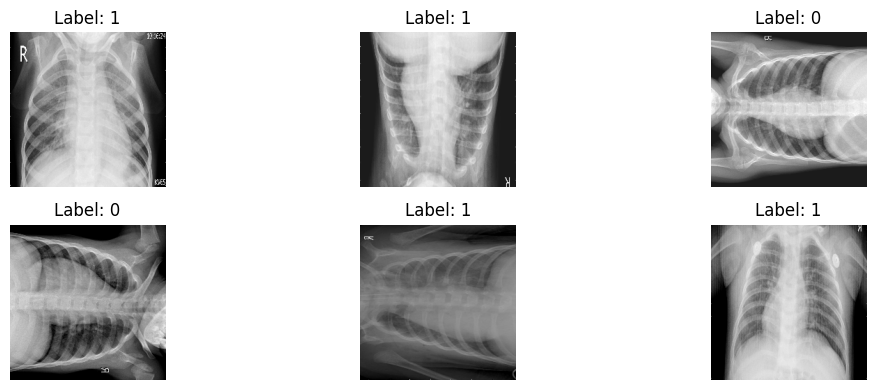

In [14]:
# Verify the preprocessing pipeline is working correctly
# Check batch shape, data type, and value ranges
# Visualize a sample batch to ensure images look correct after augmentation

sample_batch = next(iter(train_ds))
images, labels = sample_batch

print(f"Batch shape: {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Image dtype: {images.dtype}")
print(f"Image min/max: {tf.reduce_min(images):.3f} / {tf.reduce_max(images):.3f}")

plt.figure(figsize=(12, 4))
for i in range(min(6, images.shape[0])):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i].numpy().squeeze(), cmap='gray')
    plt.title(f"Label: {labels[i].numpy()}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# TRANSFER LEARNING

In [15]:
# Import necessary libraries for transfer learning

from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16, ResNet50, EfficientNetB0
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

In [16]:
def subsample_dataset(ds, fraction):
    size = tf.data.experimental.cardinality(ds).numpy()
    return ds.take(int(size * fraction))

In [17]:
# Create model via transfer learning
# Use and freeze base layers from giant, well-trained models (VGG16, ResNet50, or EfficientNetB0)
# Create additional hidden layer and a binary output layer

def create_model(base_model_name="ResNet50", input_shape=(224, 224, 3), dropout_rate=0.0, dense_units=128):
    
    inputs = keras.Input(shape=input_shape)  # create input layer

    # select base model to be used in transfer learning and preprocess data accordingly
    match base_model_name:
        case "VGG16":
            x = layers.Lambda(lambda t: vgg_preprocess(t * 255.0))(inputs)  # [0,1] -> [0,255], then VGG preprocess
            base_model = VGG16(weights="imagenet", include_top=False, input_shape=input_shape)
        case "ResNet50":
            x = layers.Lambda(lambda t: resnet_preprocess(t * 255.0))(inputs)  # [0,1] -> [0,255], then ResNet preprocess
            base_model = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
        case "EfficientNetB0":
            x = layers.Rescaling(2.0, offset=-1)(inputs)  # [0,1] -> [-1,1]
            base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=input_shape)
        case other:
            raise ValueError(f"Model '{other}' not supported.")

    base_model.trainable = False  # freeze base layers

    x = base_model(x, training=False)  # connect preprocessed inputs to all base (transer) layers

    x = layers.GlobalAveragePooling2D()(x)  # flattens feature maps to just averaged-out channels
    x = layers.Dropout(dropout_rate)(x)  # set dropout rate to 30%
    x = layers.Dense(dense_units, activation="relu")(x)  # additional layer on top of frozen layers to specify training to this dataset
    x = layers.BatchNormalization()(x) # batch normalization

    outputs = layers.Dense(1, activation="sigmoid")(x)  # output layer with sigmoid activation func for binary classification

    model = Model(inputs, outputs)  # build model
    return model

In [18]:
def test_dropout(dropout_rate, epochs=10):
    train_ds_small = subsample_dataset(train_ds, 0.1)
    val_ds_small   = subsample_dataset(val_ds, 0.1)
    test_ds_small  = subsample_dataset(test_ds, 0.1)

    model1 = create_model(
        base_model_name="ResNet50",
        dropout_rate=dropout_rate
    )

    model1.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )

    model1.fit(
        train_ds_small,
        validation_data=val_ds_small,
        epochs=epochs,
        class_weight=class_weights,
        verbose=0
    )

    metrics = model1.evaluate(test_ds_small, verbose=0)

    return model1, dict(zip(model1.metrics_names, metrics))

In [19]:
results = {}
dropout_rates = [0.3, 0.4, 0.5, 0.6, 0.7]

for rate in dropout_rates:
    print(f"Testing dropout = {rate}")
    history, metrics = test_dropout(rate)
    results[rate] = metrics

print("\nDropout Rates Results:")
results

Testing dropout = 0.3

Testing dropout = 0.4
Testing dropout = 0.5
Testing dropout = 0.6
Testing dropout = 0.7

Dropout Rates Results:


{0.3: {'loss': 0.49664461612701416, 'compile_metrics': 0.78125},
 0.4: {'loss': 0.16798461973667145, 'compile_metrics': 0.9375},
 0.5: {'loss': 0.24199368059635162, 'compile_metrics': 0.875},
 0.6: {'loss': 0.5740456581115723, 'compile_metrics': 0.75},
 0.7: {'loss': 0.7095272541046143, 'compile_metrics': 0.71875}}

In [20]:
# define model with specified pre-trained architecture
# compile model with chosen optimizer, loss function, and metrics

cnn_res = create_model(base_model_name="ResNet50", dropout_rate=0.35)
cnn_res.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy", 
        keras.metrics.AUC(name='auc'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall')
    ]
)

cnn_vgg = create_model(base_model_name="VGG16", dropout_rate=0.35)
cnn_vgg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy", 
        keras.metrics.AUC(name='auc'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

cnn_enb = create_model(base_model_name="EfficientNetB0", dropout_rate=0.35)
cnn_enb.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy", 
        keras.metrics.AUC(name='auc'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [21]:
# train model and monitor validation metrics
EPOCHS = 10

history_res = cnn_res.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights
)

Epoch 1/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.9075 - auc_roc: 0.9739 - loss: 0.2171 - precision: 0.9527 - recall: 0.8843 - val_accuracy: 0.9267 - val_auc_roc: 0.9856 - val_loss: 0.2424 - val_precision: 0.9916 - val_recall: 0.8810
Epoch 2/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.9487 - auc_roc: 0.9885 - loss: 0.1331 - precision: 0.9719 - recall: 0.9385 - val_accuracy: 0.9375 - val_auc_roc: 0.9901 - val_loss: 0.1522 - val_precision: 0.9839 - val_recall: 0.9071
Epoch 3/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 63s 926ms/step - accuracy: 0.9445 - auc_roc: 0.9874 - loss: 0.1421 - precision: 0.9647 - recall: 0.9385 - val_accuracy: 0.9483 - val_auc_roc: 0.9928 - val_loss: 0.1149 - val_precision: 0.9693 - val_recall: 0.9405
Epoch 4/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 65s 947ms/step - accuracy: 0.9528 - auc_roc: 0.9906 - loss: 0.1184 - precision: 0.9744 - recall: 0.9433 - val_accuracy: 0.9483 - val_auc_roc: 0.9907 - val_loss: 0.1269 - val_precision: 0.9658 - val_recall: 0.9442
E

In [22]:
history_vgg = cnn_vgg.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights
)

Epoch 1/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 410s 6s/step - accuracy: 0.8479 - auc_roc: 0.9268 - loss: 0.3469 - precision: 0.9003 - recall: 0.8292 - val_accuracy: 0.8922 - val_auc_roc: 0.9807 - val_loss: 0.3041 - val_precision: 0.9824 - val_recall: 0.8290
Epoch 2/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 395s 6s/step - accuracy: 0.9122 - auc_roc: 0.9693 - loss: 0.2237 - precision: 0.9418 - recall: 0.9042 - val_accuracy: 0.9418 - val_auc_roc: 0.9879 - val_loss: 0.1531 - val_precision: 0.9764 - val_recall: 0.9219
Epoch 3/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 379s 6s/step - accuracy: 0.9256 - auc_roc: 0.9755 - loss: 0.1995 - precision: 0.9498 - recall: 0.9202 - val_accuracy: 0.9461 - val_auc_roc: 0.9893 - val_loss: 0.1588 - val_precision: 0.9841 - val_recall: 0.9219
Epoch 4/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 393s 6s/step - accuracy: 0.9283 - auc_roc: 0.9757 - loss: 0.1957 - precision: 0.9522 - recall: 0.9226 - val_accuracy: 0.9073 - val_auc_roc: 0.9880 - val_loss: 0.2686 - val_precision: 1.0000 - val_recall: 0.8401
Epoc

In [23]:
history_enb = cnn_enb.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights
)

Epoch 1/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 82s 912ms/step - accuracy: 0.5016 - auc_roc: 0.5080 - loss: 0.8038 - precision: 0.5814 - recall: 0.4988 - val_accuracy: 0.4203 - val_auc_roc: 0.7484 - val_loss: 0.8013 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 58s 851ms/step - accuracy: 0.5280 - auc_roc: 0.5293 - loss: 0.7484 - precision: 0.6096 - recall: 0.5148 - val_accuracy: 0.5776 - val_auc_roc: 0.7886 - val_loss: 0.6830 - val_precision: 0.5788 - val_recall: 0.9963
Epoch 3/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 59s 855ms/step - accuracy: 0.5062 - auc_roc: 0.5174 - loss: 0.7331 - precision: 0.5805 - recall: 0.5323 - val_accuracy: 0.4203 - val_auc_roc: 0.8222 - val_loss: 0.7096 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 59s 866ms/step - accuracy: 0.5206 - auc_roc: 0.5363 - loss: 0.7195 - precision: 0.6057 - recall: 0.4940 - val_accuracy: 0.5797 - val_auc_roc: 0.8242 - val_loss: 0.6674 - val_precision: 0.5797 -

In [24]:
# Test images
models = {
    "ResNet50": cnn_res,
    "VGG16": cnn_vgg,
    "EfficientNetB0": cnn_enb
}

def prepare_single_image(image_path):
    """
    Loads, preprocesses, and adds a batch dimension to a single image 
    for prediction using the standard pipeline logic.
    """
    img = tf.io.read_file(image_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = img / 255.0  # Normalize to [0, 1]
    
    input_tensor = tf.expand_dims(img, axis=0)
    return input_tensor.numpy().astype('float32')

images = [
    ('../data/DATA/DATA/1/person1308_bacteria_3288.jpeg', 1),
    ('../data/DATA/DATA/0/NORMAL2-IM-1054-0001.jpeg', 0),
    ('../data/DATA/DATA/0/NORMAL2-IM-0927-0001.jpeg',0),
]
THRESHOLD = 0.5

for image_path, true_label in images:
    input_tensor = prepare_single_image(image_path)

    print(f"\nImage: {image_path}")
    print(f"Actual class: {true_label}")

    for model_name, model in models.items():
        prob = model.predict(input_tensor, verbose=0)[0][0]
        pred_class = int(prob >= THRESHOLD)

        print(f"  {model_name}:")
        print(f"    Predicted class: {pred_class}")
        print(f"    P(class=1): {prob:.4f}")
        print(f"    P(class=0): {1 - prob:.4f}")


Image: ../data/DATA/DATA/1/person1308_bacteria_3288.jpeg
Actual class: 1
  ResNet50:
    Predicted class: 1
    P(class=1): 0.9979
    P(class=0): 0.0021
  VGG16:
    Predicted class: 1
    P(class=1): 0.9971
    P(class=0): 0.0029
  EfficientNetB0:
    Predicted class: 0
    P(class=1): 0.4574
    P(class=0): 0.5426

Image: ../data/DATA/DATA/0/NORMAL2-IM-1054-0001.jpeg
Actual class: 0
  ResNet50:
    Predicted class: 0
    P(class=1): 0.0015
    P(class=0): 0.9985
  VGG16:
    Predicted class: 0
    P(class=1): 0.0062
    P(class=0): 0.9938
  EfficientNetB0:
    Predicted class: 0
    P(class=1): 0.4353
    P(class=0): 0.5647

Image: ../data/DATA/DATA/0/NORMAL2-IM-0927-0001.jpeg
Actual class: 0
  ResNet50:
    Predicted class: 0
    P(class=1): 0.0029
    P(class=0): 0.9971
  VGG16:
    Predicted class: 0
    P(class=1): 0.1417
    P(class=0): 0.8583
  EfficientNetB0:
    Predicted class: 0
    P(class=1): 0.4147
    P(class=0): 0.5853


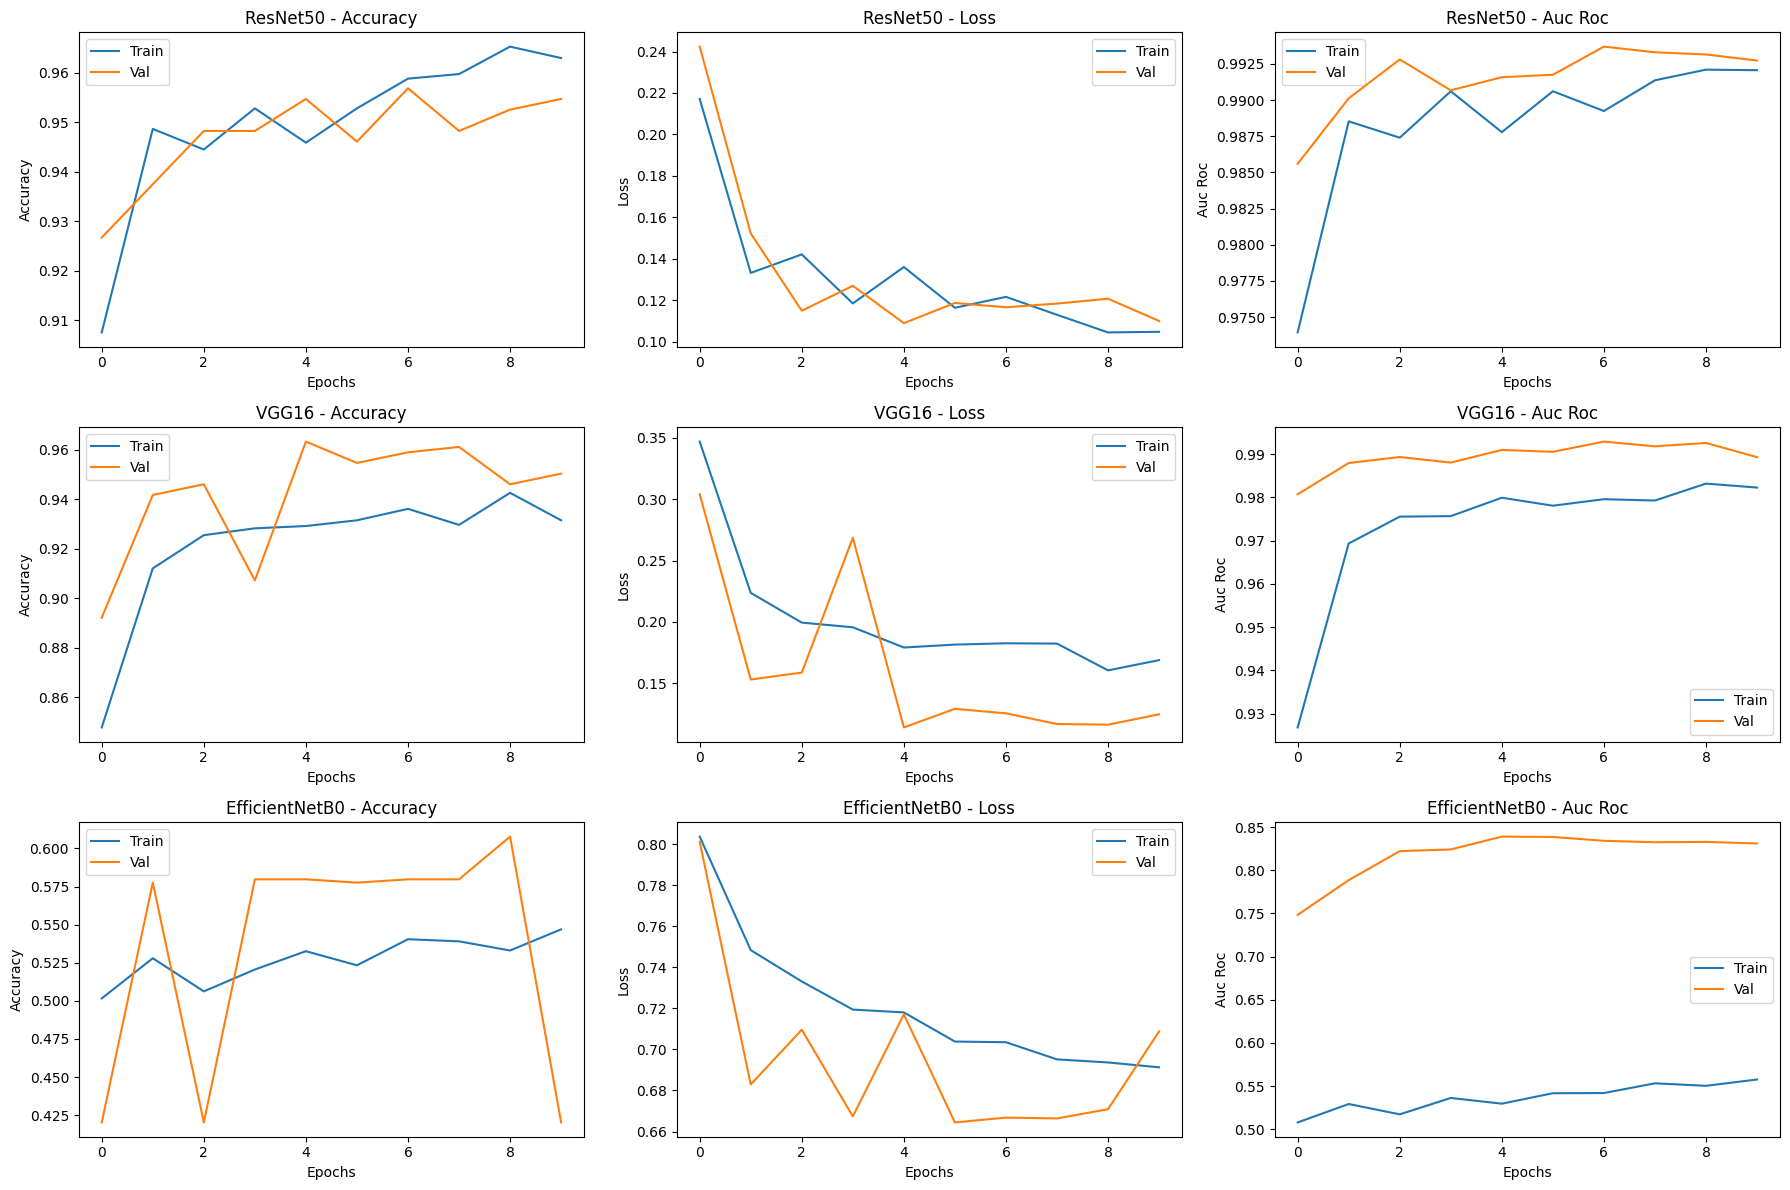

In [38]:
# Display metrics vs. epochs to determine how well the model is performing and generalizing to the validation test
histories = {
    "ResNet50": history_res,
    "VGG16": history_vgg,
    "EfficientNetB0": history_enb
}

import matplotlib.pyplot as plt

metrics_to_plot = ["accuracy", "loss", "auc_roc"]

plt.figure(figsize=(18, 12))

for row_idx, (model_name, history) in enumerate(histories.items()):
    for col_idx, metric in enumerate(metrics_to_plot):
        plt.subplot(3, 3, row_idx * 3 + col_idx + 1)

        # Training metric
        plt.plot(history.history[metric], label="Train")
        # Validation metric
        plt.plot(history.history[f"val_{metric}"], label="Val")

        plt.title(f"{model_name} - {metric.replace('_', ' ').title()}")
        plt.xlabel("Epochs")
        plt.ylabel(metric.replace('_', ' ').title())
        plt.legend()

plt.tight_layout()
plt.show()

In [39]:
# evaluate each model on test set
# check metrics: accuracy and AUC to determine performance
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score


def evaluate_model_comprehensive(model, test_ds, model_name):
    # Get Keras metrics (includes precision, recall from compilation)
    eval_results = model.evaluate(test_ds, verbose=1)

    test_loss = eval_results[0]
    test_acc = eval_results[1]
    test_auc = eval_results[2]
    test_precision = eval_results[3]
    test_recall = eval_results[4]

    # Get predictions for confusion matrix and F1 calculation
    all_predictions = []
    all_labels = []
    
    for images, labels in test_ds:
        predictions = model.predict(images, verbose=0)
        all_predictions.extend((predictions > 0.5).astype(int).flatten())
        all_labels.extend(labels.numpy())
    
    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)

    # Calculate additional metrics
    cm = confusion_matrix(all_labels, all_predictions)
    tn, fp, fn, tp = cm.ravel()
    
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = f1_score(all_labels, all_predictions)

    # print metrics
    print(f"\nAccuracy: {test_acc:.4f}")
    print(f"AUC: {test_auc:.4f}")
    print(f"Precision: {test_precision:.4f}")
    print(f"Recall: {test_recall:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"F1 Score: {f1:.4f}")

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, cmap='Blues')
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.ylabel('True Label', fontsize=12, fontweight='bold')
    plt.title(f'Confusion Matrix - {model_name}', fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

ResNet50:
15/15 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.9741 - auc_roc: 0.9959 - loss: 0.0822 - precision: 0.9812 - recall: 0.9739

Accuracy: 0.9741
AUC: 0.9959
Precision: 0.9812
Recall: 0.9739
Specificity: 0.9745
F1 Score: 0.9775


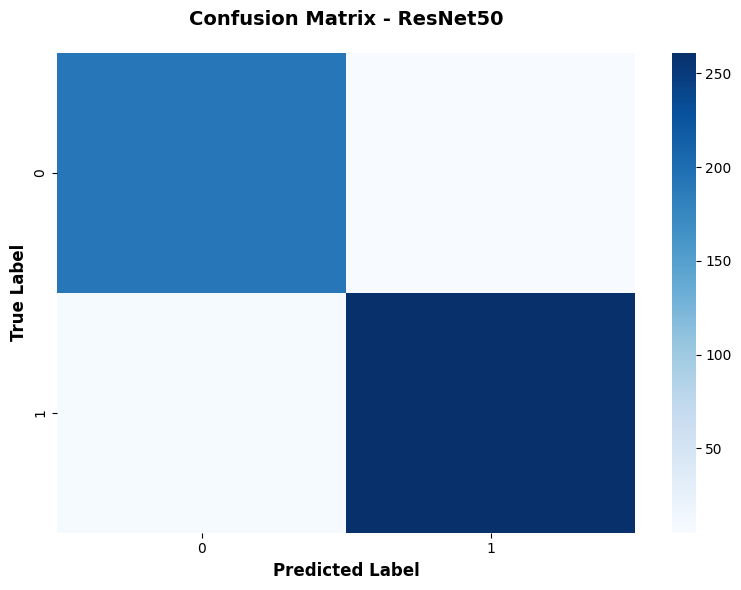

VGG16:
15/15 ━━━━━━━━━━━━━━━━━━━━ 72s 5s/step - accuracy: 0.9483 - auc_roc: 0.9876 - loss: 0.1419 - precision: 0.9803 - recall: 0.9291

Accuracy: 0.9483
AUC: 0.9876
Precision: 0.9803
Recall: 0.9291
Specificity: 0.9745
F1 Score: 0.9540


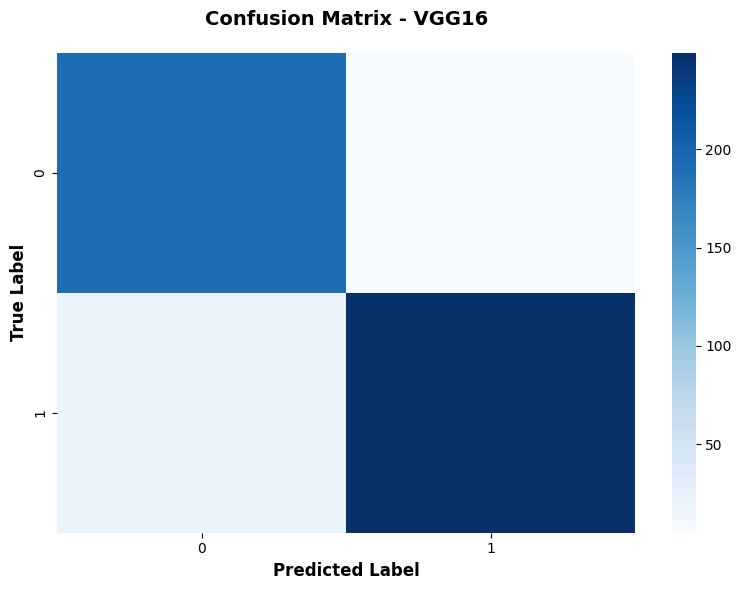

EfficientNetB0:
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 658ms/step - accuracy: 0.4224 - auc_roc: 0.8349 - loss: 0.7086 - precision: 0.0000e+00 - recall: 0.0000e+00

Accuracy: 0.4224
AUC: 0.8349
Precision: 0.0000
Recall: 0.0000
Specificity: 1.0000
F1 Score: 0.0000


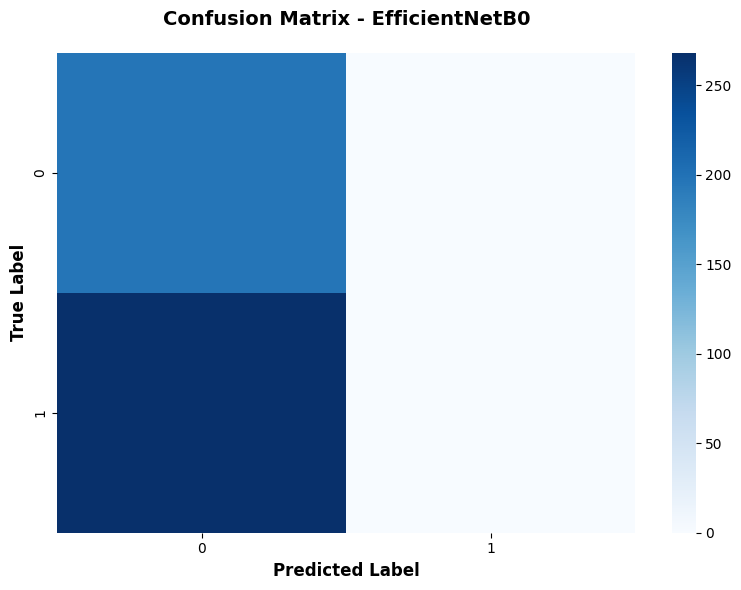

In [40]:
print("ResNet50:")
evaluate_model_comprehensive(cnn_res, test_ds, model_name="ResNet50")
print("VGG16:")
evaluate_model_comprehensive(cnn_vgg, test_ds, model_name="VGG16")
print("EfficientNetB0:")
evaluate_model_comprehensive(cnn_enb, test_ds, model_name="EfficientNetB0")

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

def get_metrics(model, X_test, y_test, probs=True):
    """
    model   : trained classifier
    X_test  : test features
    y_test  : true labels
    probs   : whether model has predict_proba
    """
    y_pred = model.predict(X_test)

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
    }

    if probs:
        y_prob = model.predict_proba(X_test)[:, 1]
        metrics["roc_auc"] = roc_auc_score(y_test, y_prob)

    return metrics

In [29]:
# comparatively
# testing SVM , random forest & logistic regression
# uses last layer from architecture
feature_extractor = keras.Model(
    inputs=cnn_res.input,
    outputs=cnn_res.layers[-2].output   # -1 = output layer, -2 = last hidden layer -> get FEATURES
)

train_ds_feat = make_dataset(train_df, shuffle=False, augment_data=False)
test_ds_feat  = make_dataset(test_df, shuffle=False, augment_data=False)

train_features = feature_extractor.predict(train_ds_feat)
test_features  = feature_extractor.predict(test_ds_feat)

y_train = train_df["class_id"].values
y_test  = test_df["class_id"].values

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# decision boundaries
svm = SVC(probability=True).fit(train_features, y_train)
lr = LogisticRegression(max_iter=500).fit(train_features, y_train)
rf = RandomForestClassifier().fit(train_features, y_train)

results = {}

results["SVM"] = get_metrics(svm, test_features, y_test)
results["Logistic Regression"] = get_metrics(lr, test_features, y_test)
results["Random Forest"] = get_metrics(rf, test_features, y_test)


df = pd.DataFrame(results).T
print(df.round(4))

68/68 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step
                     accuracy  precision  recall      f1  roc_auc
SVM                    0.9741     0.9812  0.9739  0.9775   0.9964
Logistic Regression    0.9741     0.9776  0.9776  0.9776   0.9976
Random Forest          0.9698     0.9739  0.9739  0.9739   0.9940


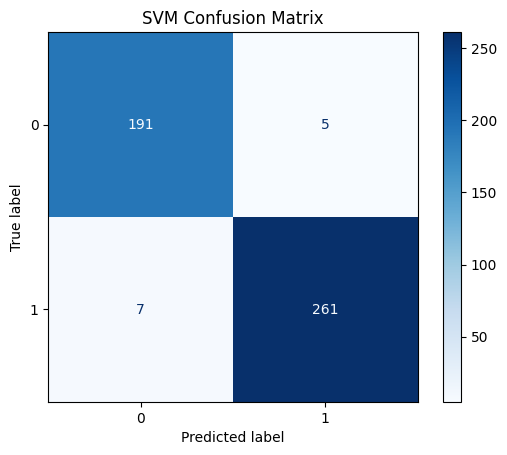

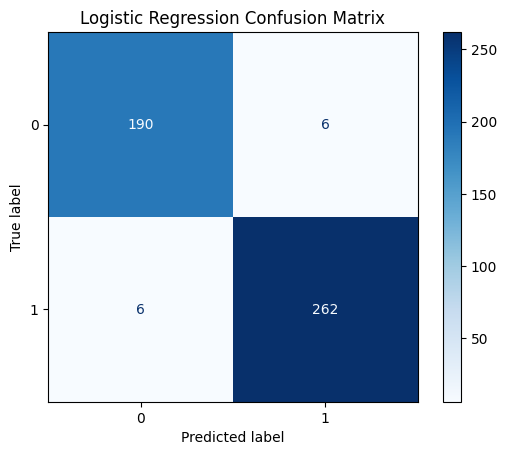

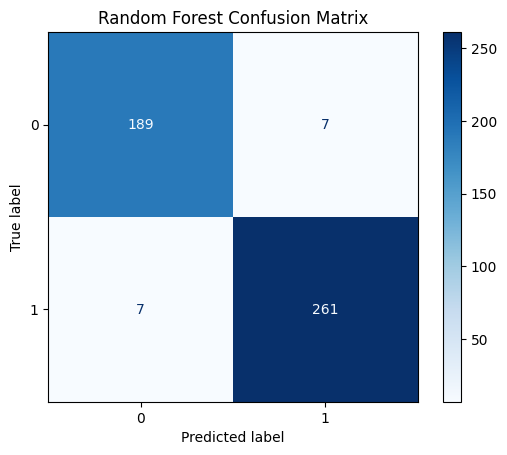

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion(model, X_test, y_test, title=None):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap="Blues", values_format="d")
    
    if title:
        plt.title(title)
    plt.show()

plot_confusion(svm, test_features, y_test, title="SVM Confusion Matrix")
plot_confusion(lr, test_features, y_test, title="Logistic Regression Confusion Matrix")
plot_confusion(rf, test_features, y_test, title="Random Forest Confusion Matrix")